# Project Overview

The aim of this project is to help you become comfortable with Python, NumPy, and basic image filtering techniques. Once you have a working image filtering routine, creating hybrid images will follow naturally. You are expected to implement five functions, each depending on the previous one:

1. **cross_correlation_2d**
2. **convolve_2d**
3. **gaussian_blur_kernel_2d**
4. **low_pass**
5. **high_pass**


• **Image Filtering**: Filtering (or convolution) is one of the most fundamental operations in image processing. For background, refer to Szeliski and the lecture slides on linear filtering. While NumPy provides fast built-in operations for filtering, in this assignment you will develop your own implementation from scratch. Start by coding `cross_correlation_2d`, then extend it to build `convolve_2d`, which will reuse the correlation function.

• **Gaussian Blur**: As covered in lectures, blurring can be performed by averaging neighboring pixel values. A Gaussian blur is a more advanced technique, where neighbors are weighted according to a Gaussian distribution. To implement this, you will write `gaussian_blur_kernel_2d`, which generates a Gaussian kernel of a specified size. This kernel can then be passed into your `convolve_2d` function, along with an image, to create a blurred version.

• **Low-Pass and High-Pass Filters**: A low-pass filter removes finer details and preserves smooth image content. A high-pass filter keeps the edges and sharp transitions, while suppressing coarse structures. Using Gaussian blur as the basis, you will implement the `low_pass` and `high_pass` functions.

• **Hybrid Images**: A hybrid image is formed by combining a low-pass filtered version of one image with a high-pass filtered version of another. This process requires choosing a parameter known as the cutoff frequency, which determines how much detail is removed or retained. The cutoff is adjusted by setting the standard deviation (σ) of the Gaussian kernel. You are encouraged to experiment with different values, and even use different cutoffs for each image.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## part 1- Cross correlation

In [2]:
def cross_correlation_2d(img, kernel, pad=True):
    """
    We do cross correlation with this func. using padding to decide if u want to have zero padding
    """
    img_h, img_w = img.shape
    kernel_h, kernel_w = kernel.shape

    if pad:
        pad_top_bot = kernel_h//2
        pad_left_right = kernel_w//2
        output_h, output_w = img_h, img_w
        img = np.pad(array=img,pad_width=(pad_top_bot, pad_left_right), constant_values=0)
    else:
        output_h, output_w = img_h - kernel_h+1, img_w-kernel_w+1
        
    output_img = np.zeros((output_h, output_w))

    for y in range(output_h):  #move down
        for x in range(output_w): #right
            img_piece = img[y:y+kernel_h, x:x+kernel_w]
            mult = np.multiply(img_piece, kernel)
            output_img[y][x] = np.sum(mult)
    
    return output_img

### testing part 1 with simple logic

In [3]:
img = np.zeros((7, 7), dtype=int)
img[3,3] = 1
kernel = np.array([[1,2,3],
                   [4,5, 6],
                   [7, 8,9]])

# print(img.shape)
# img = np.pad(img,(1, 1), constant_values=0)
# print(img.shape)

print(cross_correlation_2d(img, kernel=kernel))

[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 9. 8. 7. 0. 0.]
 [0. 0. 6. 5. 4. 0. 0.]
 [0. 0. 3. 2. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]


In [4]:
print(cross_correlation_2d(img, kernel, pad=True))

[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 9. 8. 7. 0. 0.]
 [0. 0. 6. 5. 4. 0. 0.]
 [0. 0. 3. 2. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]


In [5]:
img = np.zeros((3,3), dtype=int)
img[1,1]=1
print(cross_correlation_2d(img, kernel, pad=True))

[[9. 8. 7.]
 [6. 5. 4.]
 [3. 2. 1.]]


## Part 2: Convolve 2D

In [6]:
def convolve_2d(img, kernel, pad=True):
    impulse = np.zeros_like(kernel)
    kernel_h, kernel_w = kernel.shape
    impulse[kernel_h//2, kernel_w//2] = 1
    flipped_kernel = cross_correlation_2d(impulse, kernel, pad=True) #impulse is what my img is, need to have it samesize

    output_img = cross_correlation_2d(img, flipped_kernel, pad=pad)

    return output_img

### testing out convolve func

In [7]:
img = np.array([[10, 20 , 30],
               [40, 50, 60],
               [70, 80, 90]])
kernel = np.array([[1, 2, 0],
                   [3, 4, 0],
                   [0,0,0]])

print(convolve_2d(img, kernel, True))

[[230. 330. 240.]
 [530. 630. 420.]
 [520. 590. 360.]]


## Part 3: Gaussian blur

In [30]:
def gaussian_blur_kernel_2d(size, sigma):
    center_x = (size-1)/2
    center_y = (size-1)/2

    n = size//2
    coords = np.linspace(-n, n, size)

    xx, yy = np.meshgrid(coords, coords)

    gaussian_f = (1/(2*np.pi*sigma*sigma))*(np.exp(-(xx*xx + yy*yy)/(2*sigma*sigma)))

    gaus_sum = np.sum(gaussian_f)
    gaussian_f = gaussian_f/gaus_sum
    return gaussian_f

### testing out the function

In [42]:
print(kernel)

[[0.00048091 0.00501119 0.01094545 0.00501119 0.00048091]
 [0.00501119 0.0522178  0.11405416 0.0522178  0.00501119]
 [0.01094545 0.11405416 0.2491172  0.11405416 0.01094545]
 [0.00501119 0.0522178  0.11405416 0.0522178  0.00501119]
 [0.00048091 0.00501119 0.01094545 0.00501119 0.00048091]]


Sum: 1.0000000000000002


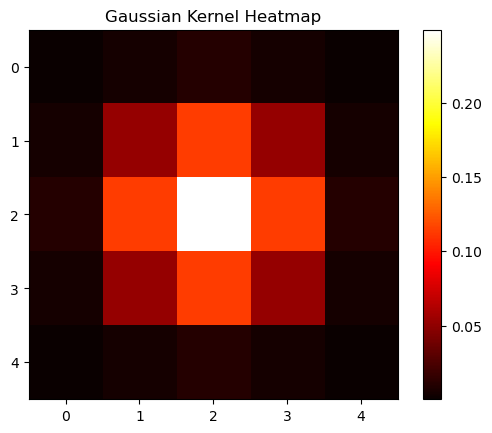

In [44]:
# Plotting the Gaussian kernel heatmap
kernel = gaussian_blur_kernel_2d(5, 0.8)
print("Sum:", np.sum(kernel))
plt.imshow(kernel, cmap='hot')
plt.colorbar()
plt.title("Gaussian Kernel Heatmap")
plt.show()

### Part 3: a- Low pass filter

In [67]:
# plot gaussian kernel or img for convinence
def plot_matrix(kernel):
    print("Sum:", np.sum(kernel))
    plt.figure(figsize=(3,3))
    plt.imshow(kernel, cmap='hot')
    plt.colorbar()
    plt.show()

In [68]:
def low_pass(img, k_size, k_sigma, pad=True):
    kernel = gaussian_blur_kernel_2d(k_size, k_sigma)
    plot_matrix(kernel)

    filtered_img = convolve_2d(img, kernel, pad=pad)

    return filtered_img

Original Matrix:
Sum: 29


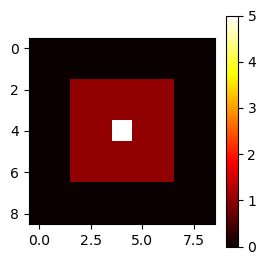

Sum: 1.0


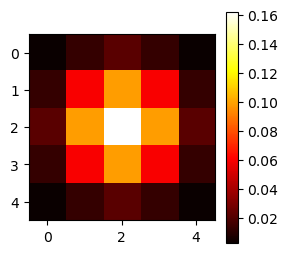

Blurred Matrix:
Sum: 29.000000000000004


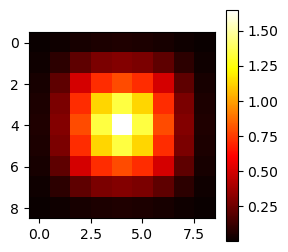

In [69]:
img = np.zeros((9, 9), dtype=int)
img[2:7, 2:7] = 1  # Create a square in the center
img[4, 4] = 5  # Add a distinct point in the center for emphasis

print("Original Matrix:")
plot_matrix(img)

# Apply the low_pass function to see the effect of Gaussian blur
blurred_img = low_pass(img, 5, 1)
print("Blurred Matrix:")
plot_matrix(blurred_img)

### Part 3: b- High pass filter

In [70]:
def high_pass(img, k_size, k_sigma, pad=True):
    kernel = gaussian_blur_kernel_2d(k_size, k_sigma)
    plot_matrix(kernel)

    filtered_img = convolve_2d(img, kernel, pad=pad)

    return (img-filtered_img)

### some testing of the high pass and low pass

Original Matrix:
Sum: 29


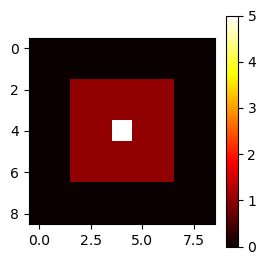

Sum: 1.0


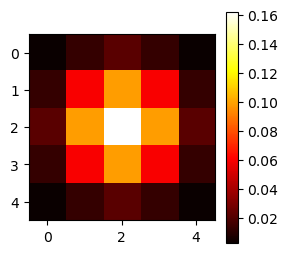

Blurred Matrix:
Sum: 3.950832716537178e-16


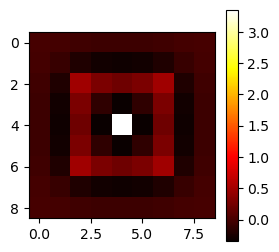

In [71]:
img = np.zeros((9, 9), dtype=int)
img[2:7, 2:7] = 1  # Create a square in the center
img[4, 4] = 5  # Add a distinct point in the center for emphasis

print("Original Matrix:")
plot_matrix(img)

# Apply the high function to see the effect of Gaussian blur
blurred_img = high_pass(img, 5, 1)
print("Blurred Matrix:")
plot_matrix(blurred_img)

## Part 4: Generatation of hybrid images